# Bucket sort

Reparte $n$ valores en $k$ cubetas según su rango (por ejemplo, $\lfloor k \cdot x \rfloor$ para $x \in [0, 1)$), ordena cada cubeta con un algoritmo simple y las concatena. Si los datos están repartidos de forma uniforme, cada cubeta recibe $O(1)$ elementos y el coste medio es $O(n + k)$; si se amontonan en pocas cubetas, degenera al coste del algoritmo interno, $O(n^2)$ con inserción.

## 1. Bucket sort de reales en [0, 1)

Implementar bucket sort con $n$ cubetas e inserción dentro de cada una y comprobarlo contra `sorted`.

In [1]:
import random

import matplotlib.pyplot as plt

def insercion(l):
    for i in range(1, len(l)):
        valor, j = l[i], i - 1
        while j >= 0 and l[j] > valor:
            l[j + 1] = l[j]
            j -= 1
        l[j + 1] = valor
    return l

def bucket_sort(lista, k=None):
    k = k or max(len(lista), 1)
    cubetas = [[] for _ in range(k)]
    for x in lista:
        cubetas[int(k * x)].append(x)
    return [x for cubeta in cubetas for x in insercion(cubeta)]

print(bucket_sort([0.78, 0.17, 0.39, 0.26, 0.72, 0.94, 0.21, 0.12, 0.23, 0.68]))
random.seed(1)
for _ in range(300):
    datos = [random.random() for _ in range(random.randint(0, 60))]
    assert bucket_sort(datos) == sorted(datos)

[0.12, 0.17, 0.21, 0.23, 0.26, 0.39, 0.68, 0.72, 0.78, 0.94]


## 2. Cualquier rango

Generalizar bucket sort a números de cualquier rango normalizando con el mínimo y el máximo, y usarlo para ordenar temperaturas.

In [2]:
def bucket_sort_rango(lista, k=10):
    if len(lista) < 2:
        return lista[:]
    minimo, maximo = min(lista), max(lista)
    if minimo == maximo:
        return lista[:]
    ancho = (maximo - minimo) / k
    cubetas = [[] for _ in range(k)]
    for x in lista:
        cubetas[min(int((x - minimo) / ancho), k - 1)].append(x)
    return [x for cubeta in cubetas for x in insercion(cubeta)]

temperaturas = [21.3, 18.7, 25.1, -2.4, 30.0, 14.8, 21.3, 9.6]
print(bucket_sort_rango(temperaturas, k=4))
for _ in range(300):
    datos = [random.uniform(-100, 100) for _ in range(random.randint(0, 60))]
    assert bucket_sort_rango(datos) == sorted(datos)

[-2.4, 9.6, 14.8, 18.7, 21.3, 21.3, 25.1, 30.0]


## 3. Uniforme frente a amontonado

Contar cuántos elementos acaban en la cubeta más llena y cuántos desplazamientos hace la inserción con datos uniformes y con datos de una normal muy estrecha (casi todos en las mismas cubetas). Dibujar el reparto de ambos casos.

uniforme    cubeta más llena:   122, desplazamientos aprox.: 251,867
amontonado  cubeta más llena:  5087, desplazamientos aprox.: 12,498,873


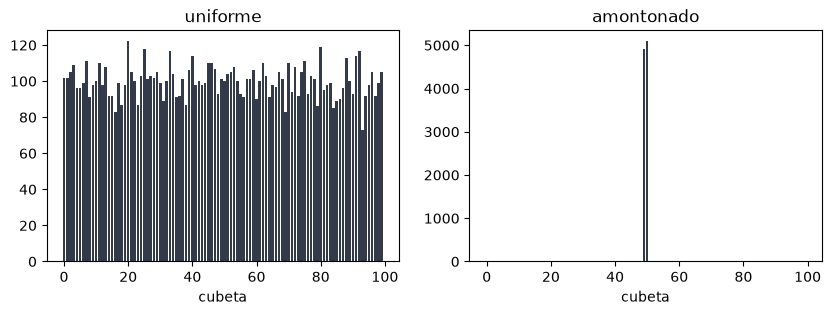

In [3]:
def reparto(lista, k):
    minimo, maximo = min(lista), max(lista)
    ancho = (maximo - minimo) / k
    tamanos = [0] * k
    for x in lista:
        tamanos[min(int((x - minimo) / ancho), k - 1)] += 1
    return tamanos

n = 10_000
random.seed(2)
casos = {"uniforme": [random.random() for _ in range(n)],
         "amontonado": [random.gauss(0.5, 0.002) for _ in range(n - 2)] + [0.0, 1.0]}

fig, ejes = plt.subplots(1, 2, figsize=(10, 3))
for eje, (nombre, datos) in zip(ejes, casos.items()):
    tamanos = reparto(datos, 100)
    # la inserción en una cubeta de m elementos hace del orden de m²/4 desplazamientos
    trabajo = sum(m * m / 4 for m in tamanos)
    print(f"{nombre:<11} cubeta más llena: {max(tamanos):>5}, desplazamientos aprox.: {trabajo:,.0f}")
    eje.bar(range(100), tamanos, color="#333b4b")
    eje.set_title(nombre)
    eje.set_xlabel("cubeta")
plt.show()

## 4. Ordenar notas con cubetas enteras

Las notas de un examen son enteros de 0 a 10. Agrupar a los alumnos en 11 cubetas por nota y obtener la lista ordenada de mayor a menor manteniendo el orden alfabético dentro de cada nota (la ordenación es estable si cada cubeta conserva el orden de llegada).

In [4]:
alumnos = sorted([("Ana", 7), ("Luis", 9), ("Eva", 5), ("Pau", 7), ("Iker", 3), ("Noa", 9), ("Bea", 10)])
cubetas = [[] for _ in range(11)]
for nombre, nota in alumnos:
    cubetas[nota].append((nombre, nota))
ordenados = [a for cubeta in reversed(cubetas) for a in cubeta]
print(ordenados)
assert ordenados == sorted(alumnos, key=lambda a: -a[1])

[('Bea', 10), ('Luis', 9), ('Noa', 9), ('Ana', 7), ('Pau', 7), ('Eva', 5), ('Iker', 3)]
